# <font color='darkblue'>*Marina Napoleão - EBAC*</font>
## <font color='darkblue'>Projeto: Previsão de Intenção de Compra de Clientes em Loja Web</font>

# **Projeto: Previsão de Intenção de Compra de Clientes em Loja Web**

**Descrição do Projeto**

Neste projeto, nosso objetivo é criar um sistema inteligente para antecipar a intenção de compra dos clientes em um site de e-commerce. Imagine poder prever quais clientes têm maior probabilidade de realizar compras online, com base em suas características e comportamentos passados. Essa capacidade de prever a intenção de compra não só aprimorará a experiência do cliente, mas também permitirá que a empresa direcione seus esforços de marketing de forma mais eficaz.

**Objetivo**

Queremos desenvolver um modelo preditivo capaz de analisar os padrões de comportamento dos clientes e identificar sinais que indicam a propensão deles para realizar compras no site da empresa. Para isso, vamos usar uma base de dados que contém informações detalhadas sobre os clientes, incluindo:

Dados demográficos (idade, renda, etc.)

Informações sobre compras anteriores

# Base de dados:

Year_Birth: Ano de nascimento do cliente.

Education: Nível de escolaridade do cliente.

Marital_Status: Estado civil do cliente.

Income: Renda anual da família do cliente.

Kidhome: Número de crianças na casa do cliente.

Recency: Número de dias desde a última compra do cliente.

Complain: 1 se o cliente reclamou nos últimos 2 anos, 0 caso contrário.

MntWines: Valor gasto em vinhos nos últimos 2 anos.

MntFruits: Valor gasto em frutas nos últimos 2 anos.

MntMeatProducts: Valor gasto em carnes nos últimos 2 anos.

MntFishProducts: Valor gasto em peixes nos últimos 2 anos.

MntSweetProducts: Valor gasto em doces nos últimos 2 anos.

MntGoldProds: Valor gasto em produtos de ouro nos últimos 2 anos.

NumDealsPurchases: Número de compras feitas com desconto

NumStorePurchases: Número de compras feitas diretamente nas lojas.

NumWebVisitsMonth: Número de visitas ao site da empresa no último mês.

WebPurchases: Número de compras feitas pelo site da empresa.

In [56]:
# Bibliotecas para manipulação de dados
import pandas as pd
import numpy as np

# Bibliotecas para visualização de dados
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

# Bibliotecas para pré-processamento e divisão de dados
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline
from sklearn.pipeline import make_pipeline

# Bibliotecas para os modelos de machine learning
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold
from scipy.stats import randint
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.decomposition import PCA

# Bibliotecas para métricas de avaliação
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_auc_score, roc_curve, auc, average_precision_score, precision_recall_curve

#Bibliotecas para KMeans
from sklearn.cluster import KMeans

#Bibliotecas para Random Forest - Regressão
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import RandomizedSearchCV

from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import cross_validate


# ETAPA 1:

**Preparação dos Dados**

**Exploração e Limpeza:** Analisar e limpar os dados para garantir que estejam prontos para a modelagem.

In [2]:
base = pd.read_csv('marketing_campaign.csv', delimiter=';')

In [3]:
#Vizualizar todas as colunas do dataset
base.head(10)

,Year_Birth,Education,Marital_Status,Income,Kidhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumStorePurchases,NumWebVisitsMonth,Complain,WebPurchases
0,1957,Graduation,Single,58138.0,0,58,635,88,546,172,88,88,4,7,0,1
1,1954,Graduation,Single,46344.0,1,38,11,1,6,2,1,6,2,5,0,0
2,1965,Graduation,Together,71613.0,0,26,426,49,127,111,21,42,10,4,0,1
3,1984,Graduation,Together,26646.0,1,26,11,4,20,10,3,5,4,6,0,0
4,1981,PhD,Married,58293.0,1,94,173,43,118,46,27,15,6,5,0,1
5,1967,Master,Together,62513.0,0,16,520,42,98,0,42,14,10,6,0,1
6,1971,Graduation,Divorced,55635.0,0,34,235,65,164,50,49,27,7,6,0,1
7,1985,PhD,Married,33454.0,1,32,76,10,56,3,1,23,4,8,0,1
8,1974,PhD,Together,30351.0,1,19,14,0,24,3,3,2,2,9,0,0
9,1950,PhD,Together,5648.0,1,68,28,0,6,1,1,13,0,20,0,0


In [4]:
#Verificar os tipos de dados
base.dtypes

Year_Birth             int64
Education             object
Marital_Status        object
Income               float64
Kidhome                int64
Recency                int64
MntWines               int64
MntFruits              int64
MntMeatProducts        int64
MntFishProducts        int64
MntSweetProducts       int64
MntGoldProds           int64
NumStorePurchases      int64
NumWebVisitsMonth      int64
Complain               int64
WebPurchases           int64
dtype: object

In [5]:
#Verificar os dados faltantes, se houver dados faltantes fazer a substituição ou remoção justificando sua escolha.
print(base.info(), '\n número de valores faltantes em cada coluna: \n', base.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Year_Birth         2240 non-null   int64  
 1   Education          2240 non-null   object 
 2   Marital_Status     2240 non-null   object 
 3   Income             2216 non-null   float64
 4   Kidhome            2240 non-null   int64  
 5   Recency            2240 non-null   int64  
 6   MntWines           2240 non-null   int64  
 7   MntFruits          2240 non-null   int64  
 8   MntMeatProducts    2240 non-null   int64  
 9   MntFishProducts    2240 non-null   int64  
 10  MntSweetProducts   2240 non-null   int64  
 11  MntGoldProds       2240 non-null   int64  
 12  NumStorePurchases  2240 non-null   int64  
 13  NumWebVisitsMonth  2240 non-null   int64  
 14  Complain           2240 non-null   int64  
 15  WebPurchases       2240 non-null   int64  
dtypes: float64(1), int64(13)

média: 52247.25135379061 
mediana: 51381.5


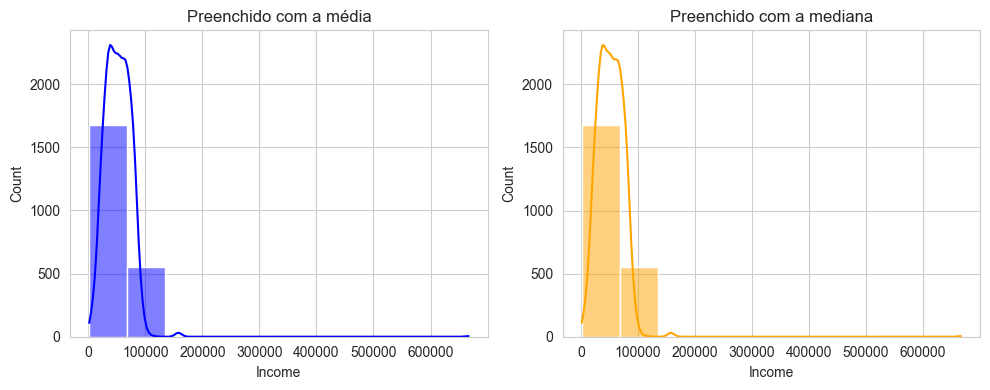

In [6]:
media_Income = base['Income'].mean()
mediana_Income = base['Income'].median()
print('média:', media_Income, '\nmediana:', mediana_Income)

base_media_Income = base['Income'].fillna(base['Income'].mean())
base_mediana_Income = base['Income'].fillna(base['Income'].median())
sns.set_style('whitegrid')

# Gráfico da média e mediana
plt.figure(figsize = (10,4))
plt.subplot(1,2,1)
sns.histplot(base_media_Income, bins = 10, kde = True, color = 'blue')
plt.title('Preenchido com a média')

plt.subplot(1,2,2)
sns.histplot(base_mediana_Income, bins = 10, kde = True, color = 'orange')
plt.title('Preenchido com a mediana')

plt.tight_layout()
plt.show()

* A decisão tomada foi preencher os dados faltantes coma mediana.

In [7]:
dados_faltantes_Income = base['Income'].median()
base['Income'].fillna(dados_faltantes_Income, inplace = True)

A = base['Income'].isnull().mean()
B = base['Income'].median()
print('\n', A, '\n', B)


 0.0 
 51381.5


C:\Users\marina\AppData\Local\Temp\ipykernel_5100\3124942623.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  base['Income'].fillna(dados_faltantes_Income, inplace = True)



 0.0 
 0.0 
 57.723214285714285 
 1.25


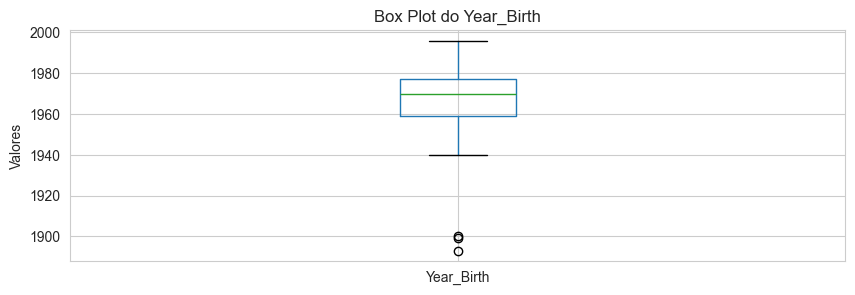

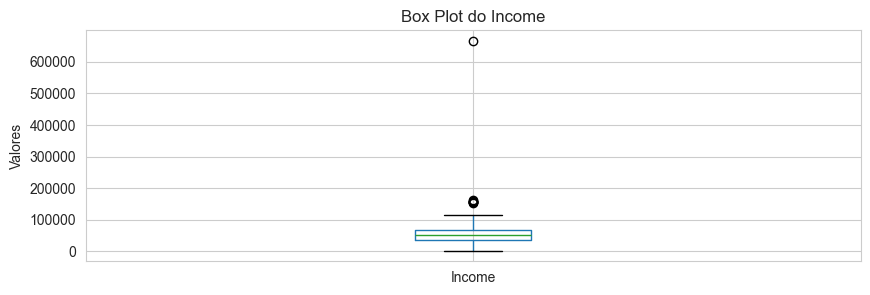

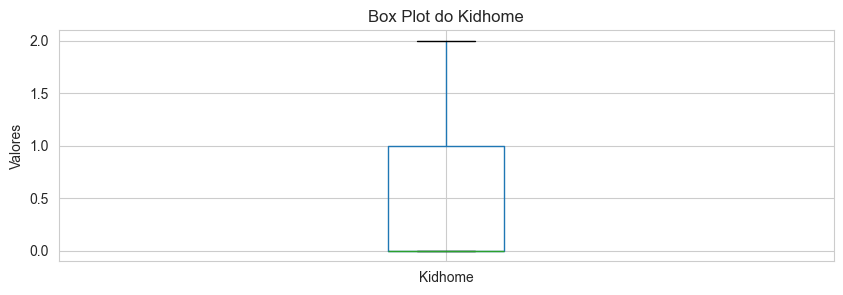

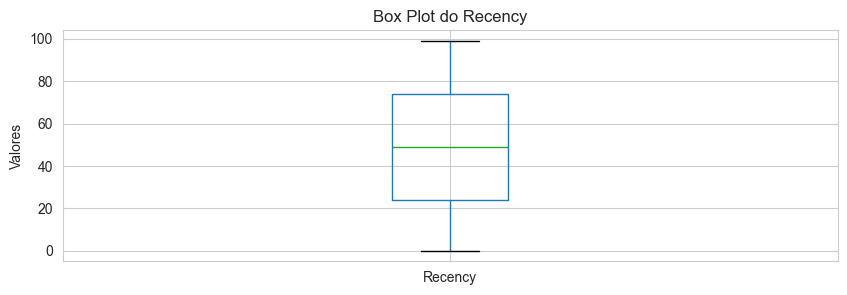

In [8]:
#Plotar graficos boxplot para identificar outliers e fazer o tratamento.
a = (base['Year_Birth'] == 0).mean() * 100  #média em porcentagem
b = (base['Income'] == 0).mean() * 100  #média em porcentagem
c = (base['Kidhome'] == 0).mean() * 100  #média em porcentagem
d = (base['Recency'] == 0).mean() * 100  #média em porcentagem
print('\n', a, '\n', b, '\n', c, '\n', d)

#grafico boxplot do 'Year_Birth'
plt.figure(figsize=(10, 3))
base.boxplot(column='Year_Birth')
plt.title('Box Plot do Year_Birth')
plt.ylabel('Valores')
plt.show()

#grafico boxplot do 'Income'
plt.figure(figsize=(10, 3))
base.boxplot(column='Income')
plt.title('Box Plot do Income')
plt.ylabel('Valores')
plt.show()

#grafico boxplot do 'Kidhome'
plt.figure(figsize=(10, 3))
base.boxplot(column='Kidhome')
plt.title('Box Plot do Kidhome')
plt.ylabel('Valores')
plt.show()

#grafico boxplot do 'Recency'
plt.figure(figsize=(10, 3))
base.boxplot(column='Recency')
plt.title('Box Plot do Recency')
plt.ylabel('Valores')
plt.show()


 0.5803571428571429 
 17.857142857142858 
 0.044642857142857144 
 18.705357142857142


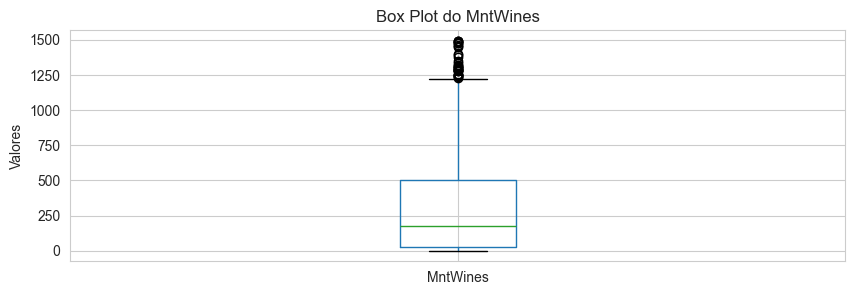

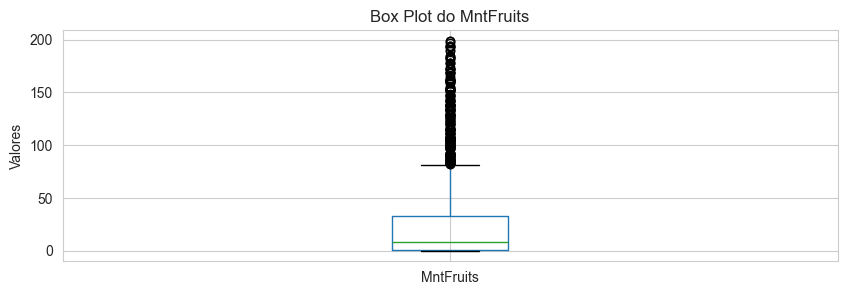

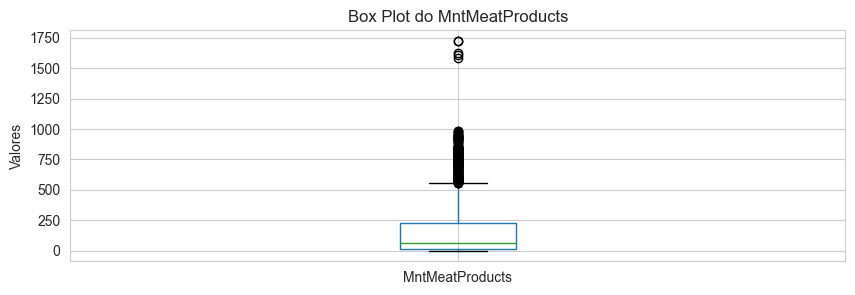

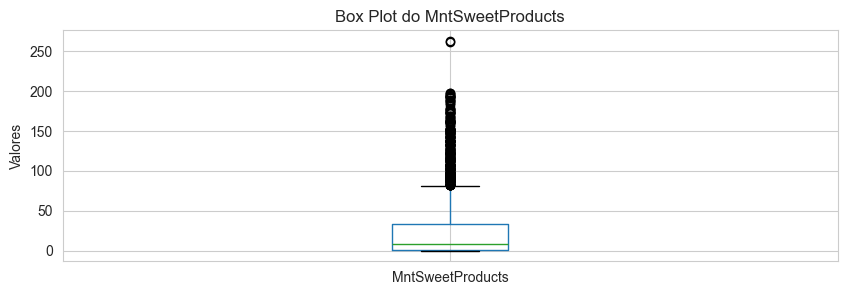

In [9]:
#Plotar graficos boxplot para identificar outliers e fazer o tratamento.
e = (base['MntWines'] == 0).mean() * 100  #média em porcentagem
f = (base['MntFruits'] == 0).mean() * 100  #média em porcentagem
g = (base['MntMeatProducts'] == 0).mean() * 100  #média em porcentagem
h = (base['MntSweetProducts'] == 0).mean() * 100  #média em porcentagem
print('\n', e, '\n', f, '\n', g, '\n', h)

#grafico boxplot do 'MntWines'
plt.figure(figsize=(10, 3))
base.boxplot(column='MntWines')
plt.title('Box Plot do MntWines')
plt.ylabel('Valores')
plt.show()

#grafico boxplot do 'MntFruits'
plt.figure(figsize=(10, 3))
base.boxplot(column='MntFruits')
plt.title('Box Plot do MntFruits')
plt.ylabel('Valores')
plt.show()

#grafico boxplot do 'MntMeatProducts'
plt.figure(figsize=(10, 3))
base.boxplot(column='MntMeatProducts')
plt.title('Box Plot do MntMeatProducts')
plt.ylabel('Valores')
plt.show()

#grafico boxplot do 'MntSweetProducts'
plt.figure(figsize=(10, 3))
base.boxplot(column='MntSweetProducts')
plt.title('Box Plot do MntSweetProducts')
plt.ylabel('Valores')
plt.show()


 2.7232142857142856 
 0.6696428571428571 
 0.49107142857142855 
 49.642857142857146


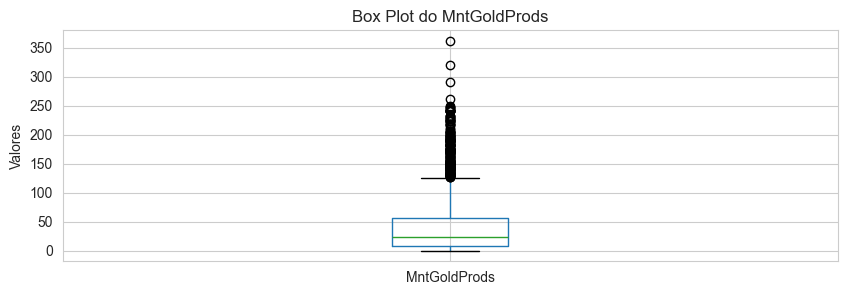

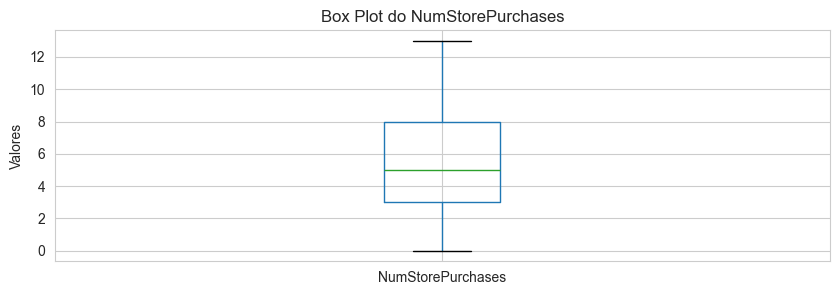

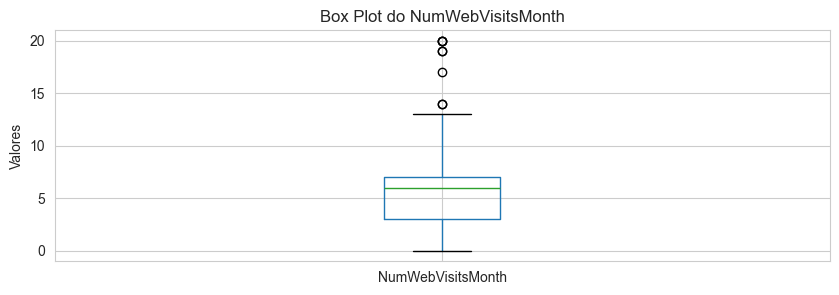

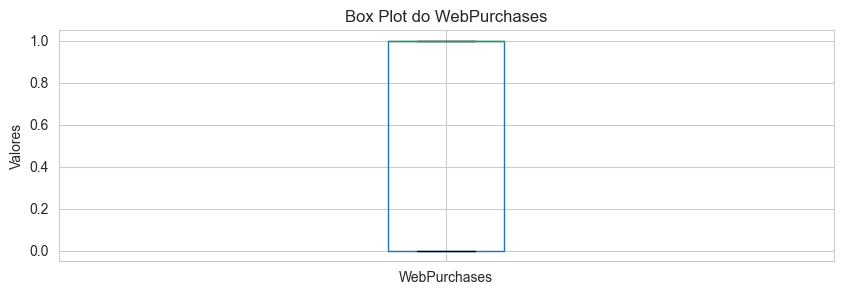

In [10]:
#Plotar graficos boxplot para identificar outliers e fazer o tratamento.
i = (base['MntGoldProds'] == 0).mean() * 100  #média em porcentagem
j = (base['NumStorePurchases'] == 0).mean() * 100  #média em porcentagem
k = (base['NumWebVisitsMonth'] == 0).mean() * 100  #média em porcentagem
l = (base['WebPurchases'] == 0).mean() * 100  #média em porcentagem

print('\n', i, '\n', j, '\n', k, '\n', l,)

#grafico boxplot do 'MntGoldProds'
plt.figure(figsize=(10, 3))
base.boxplot(column='MntGoldProds')
plt.title('Box Plot do MntGoldProds')
plt.ylabel('Valores')
plt.show()

#grafico boxplot do 'NumStorePurchases'
plt.figure(figsize=(10, 3))
base.boxplot(column='NumStorePurchases')
plt.title('Box Plot do NumStorePurchases')
plt.ylabel('Valores')
plt.show()

#grafico boxplot do 'NumWebVisitsMonth'
plt.figure(figsize=(10, 3))
base.boxplot(column='NumWebVisitsMonth')
plt.title('Box Plot do NumWebVisitsMonth')
plt.ylabel('Valores')
plt.show()

#grafico boxplot do 'WebPurchases'
plt.figure(figsize=(10, 3))
base.boxplot(column='WebPurchases')
plt.title('Box Plot do WebPurchases')
plt.ylabel('Valores')
plt.show()

In [11]:
#Calcular IRQ, limite superior, limite inferior, outliers e valores impossíveis.
coluna = 'Year_Birth'

Q1 = base[coluna].quantile(0.25)
Q3 = base[coluna].quantile(0.75)
IRQ = Q3 - Q1

limite_inferior = Q1 - 1.5 * IRQ
limite_superior = Q3 + 1.5 * IRQ

print('\n Q1:', Q1, '\n Q3:', Q3, '\n IRQ:', IRQ)
print('\n Limite inferior:', limite_inferior)
print('\n Limite superior:', limite_superior)

outliers = base[(base[coluna] < limite_inferior) | (base[coluna] > limite_superior)]

impossiveis = base[(base[coluna] <= limite_inferior) | (base[coluna] > limite_superior)]
print("total fixed acidity impossíveis:", impossiveis.shape[0])

print('\n Colunas analisadas:', coluna)
print('\n Total de outliers presente:', outliers.shape[0])


 Q1: 1959.0 
 Q3: 1977.0 
 IRQ: 18.0

 Limite inferior: 1932.0

 Limite superior: 2004.0
total fixed acidity impossíveis: 3

 Colunas analisadas: Year_Birth

 Total de outliers presente: 3


In [12]:
#Visualizar apenas os valores consideradas outliers pelo método IQR da 'Year_Birth'
outliers_year = base[(base['Year_Birth'] < limite_inferior) | (base['Year_Birth'] > limite_superior)]
print(outliers_year[['Year_Birth']])

     Year_Birth
192        1900
239        1893
339        1899


In [13]:
base = base[~base['Year_Birth'].isin([1900, 1893, 1899])]

In [14]:
#Calcular IRQ, limite superior, limite inferior, outliers e valores impossíveis.
coluna = 'Income'

Q1 = base[coluna].quantile(0.25)
Q3 = base[coluna].quantile(0.75)
IRQ = Q3 - Q1

limite_inferior = Q1 - 1.5 * IRQ
limite_superior = Q3 + 1.5 * IRQ

print('\n Q1:', Q1, '\n Q3:', Q3, '\n IRQ:', IRQ)
print('\n Limite inferior:', limite_inferior)
print('\n Limite superior:', limite_superior)

outliers = base[(base[coluna] < limite_inferior) | (base[coluna] > limite_superior)]

impossiveis = base[(base[coluna] <= limite_inferior) | (base[coluna] > limite_superior)]
print("total Income impossíveis:", impossiveis.shape[0])

print('\n Colunas analisadas:', coluna)
print('\n Total de outliers presente:', outliers.shape[0])


 Q1: 35523.0 
 Q3: 68281.0 
 IRQ: 32758.0

 Limite inferior: -13614.0

 Limite superior: 117418.0
total Income impossíveis: 8

 Colunas analisadas: Income

 Total de outliers presente: 8


In [15]:
#Visualizar apenas os valores consideradas outliers pelo método IQR da 'Income'
outliers_annual = base[(base['Income'] < limite_inferior) | (base['Income'] > limite_superior)]
print(outliers_annual[['Income']])

        Income
164   157243.0
617   162397.0
655   153924.0
687   160803.0
1300  157733.0
1653  157146.0
2132  156924.0
2233  666666.0


In [16]:
#Calcular IRQ, limite superior, limite inferior, outliers e valores impossíveis.
coluna = 'Kidhome'

Q1 = base[coluna].quantile(0.25)
Q3 = base[coluna].quantile(0.75)
IRQ = Q3 - Q1

limite_inferior = Q1 - 1.5 * IRQ
limite_superior = Q3 + 1.5 * IRQ

print('\n Q1:', Q1, '\n Q3:', Q3, '\n IRQ:', IRQ)
print('\n Limite inferior:', limite_inferior)
print('\n Limite superior:', limite_superior)

outliers = base[(base[coluna] < limite_inferior) | (base[coluna] > limite_superior)]

impossiveis = base[(base[coluna] <= limite_inferior) | (base[coluna] > limite_superior)]
print("total Kidhome impossíveis:", impossiveis.shape[0])

print('\n Colunas analisadas:', coluna)
print('\n Total de outliers presente:', outliers.shape[0])


 Q1: 0.0 
 Q3: 1.0 
 IRQ: 1.0

 Limite inferior: -1.5

 Limite superior: 2.5
total Kidhome impossíveis: 0

 Colunas analisadas: Kidhome

 Total de outliers presente: 0


In [17]:
#Calcular IRQ, limite superior, limite inferior, outliers e valores impossíveis.
coluna = 'Recency'

Q1 = base[coluna].quantile(0.25)
Q3 = base[coluna].quantile(0.75)
IRQ = Q3 - Q1

limite_inferior = Q1 - 1.5 * IRQ
limite_superior = Q3 + 1.5 * IRQ

print('\n Q1:', Q1, '\n Q3:', Q3, '\n IRQ:', IRQ)
print('\n Limite inferior:', limite_inferior)
print('\n Limite superior:', limite_superior)

outliers = base[(base[coluna] < limite_inferior) | (base[coluna] > limite_superior)]

impossiveis = base[(base[coluna] <= limite_inferior) | (base[coluna] > limite_superior)]
print("total Kidhome impossíveis:", impossiveis.shape[0])

print('\n Colunas analisadas:', coluna)
print('\n Total de outliers presente:', outliers.shape[0])


 Q1: 24.0 
 Q3: 74.0 
 IRQ: 50.0

 Limite inferior: -51.0

 Limite superior: 149.0
total Kidhome impossíveis: 0

 Colunas analisadas: Recency

 Total de outliers presente: 0


In [18]:
#Calcular IRQ, limite superior, limite inferior, outliers e valores impossíveis.
coluna = 'MntWines'

Q1 = base[coluna].quantile(0.25)
Q3 = base[coluna].quantile(0.75)
IRQ = Q3 - Q1

limite_inferior = Q1 - 1.5 * IRQ
limite_superior = Q3 + 1.5 * IRQ

print('\n Q1:', Q1, '\n Q3:', Q3, '\n IRQ:', IRQ)
print('\n Limite inferior:', limite_inferior)
print('\n Limite superior:', limite_superior)

outliers = base[(base[coluna] < limite_inferior) | (base[coluna] > limite_superior)]

impossiveis = base[(base[coluna] <= limite_inferior) | (base[coluna] > limite_superior)]
print("total MntWines impossíveis:", impossiveis.shape[0])

print('\n Colunas analisadas:', coluna)
print('\n Total de outliers presente:', outliers.shape[0])


 Q1: 24.0 
 Q3: 504.0 
 IRQ: 480.0

 Limite inferior: -696.0

 Limite superior: 1224.0
total MntWines impossíveis: 35

 Colunas analisadas: MntWines

 Total de outliers presente: 35


In [19]:
#Calcular IRQ, limite superior, limite inferior, outliers e valores impossíveis.
coluna = 'MntFruits'

Q1 = base[coluna].quantile(0.25)
Q3 = base[coluna].quantile(0.75)
IRQ = Q3 - Q1

limite_inferior = Q1 - 1.5 * IRQ
limite_superior = Q3 + 1.5 * IRQ

print('\n Q1:', Q1, '\n Q3:', Q3, '\n IRQ:', IRQ)
print('\n Limite inferior:', limite_inferior)
print('\n Limite superior:', limite_superior)

outliers = base[(base[coluna] < limite_inferior) | (base[coluna] > limite_superior)]

impossiveis = base[(base[coluna] <= limite_inferior) | (base[coluna] > limite_superior)]
print("total MntFruits impossíveis:", impossiveis.shape[0])

print('\n Colunas analisadas:', coluna)
print('\n Total de outliers presente:', outliers.shape[0])


 Q1: 1.0 
 Q3: 33.0 
 IRQ: 32.0

 Limite inferior: -47.0

 Limite superior: 81.0
total MntFruits impossíveis: 226

 Colunas analisadas: MntFruits

 Total de outliers presente: 226


In [20]:
#Calcular IRQ, limite superior, limite inferior, outliers e valores impossíveis.
coluna = 'MntMeatProducts'

Q1 = base[coluna].quantile(0.25)
Q3 = base[coluna].quantile(0.75)
IRQ = Q3 - Q1

limite_inferior = Q1 - 1.5 * IRQ
limite_superior = Q3 + 1.5 * IRQ

print('\n Q1:', Q1, '\n Q3:', Q3, '\n IRQ:', IRQ)
print('\n Limite inferior:', limite_inferior)
print('\n Limite superior:', limite_superior)

outliers = base[(base[coluna] < limite_inferior) | (base[coluna] > limite_superior)]

impossiveis = base[(base[coluna] <= limite_inferior) | (base[coluna] > limite_superior)]
print("total MntMeatProducts impossíveis:", impossiveis.shape[0])

print('\n Colunas analisadas:', coluna)
print('\n Total de outliers presente:', outliers.shape[0])


 Q1: 16.0 
 Q3: 232.0 
 IRQ: 216.0

 Limite inferior: -308.0

 Limite superior: 556.0
total MntMeatProducts impossíveis: 174

 Colunas analisadas: MntMeatProducts

 Total de outliers presente: 174


In [21]:
#Calcular IRQ, limite superior, limite inferior, outliers e valores impossíveis.
coluna = 'MntFishProducts'

Q1 = base[coluna].quantile(0.25)
Q3 = base[coluna].quantile(0.75)
IRQ = Q3 - Q1

limite_inferior = Q1 - 1.5 * IRQ
limite_superior = Q3 + 1.5 * IRQ

print('\n Q1:', Q1, '\n Q3:', Q3, '\n IRQ:', IRQ)
print('\n Limite inferior:', limite_inferior)
print('\n Limite superior:', limite_superior)

outliers = base[(base[coluna] < limite_inferior) | (base[coluna] > limite_superior)]

impossiveis = base[(base[coluna] <= limite_inferior) | (base[coluna] > limite_superior)]
print("total MntFishProducts impossíveis:", impossiveis.shape[0])

print('\n Colunas analisadas:', coluna)
print('\n Total de outliers presente:', outliers.shape[0])


 Q1: 3.0 
 Q3: 50.0 
 IRQ: 47.0

 Limite inferior: -67.5

 Limite superior: 120.5
total MntFishProducts impossíveis: 223

 Colunas analisadas: MntFishProducts

 Total de outliers presente: 223


In [22]:
#Calcular IRQ, limite superior, limite inferior, outliers e valores impossíveis.
coluna = 'MntSweetProducts'

Q1 = base[coluna].quantile(0.25)
Q3 = base[coluna].quantile(0.75)
IRQ = Q3 - Q1

limite_inferior = Q1 - 1.5 * IRQ
limite_superior = Q3 + 1.5 * IRQ

print('\n Q1:', Q1, '\n Q3:', Q3, '\n IRQ:', IRQ)
print('\n Limite inferior:', limite_inferior)
print('\n Limite superior:', limite_superior)

outliers = base[(base[coluna] < limite_inferior) | (base[coluna] > limite_superior)]

impossiveis = base[(base[coluna] <= limite_inferior) | (base[coluna] > limite_superior)]
print("total MntSweetProducts impossíveis:", impossiveis.shape[0])

print('\n Colunas analisadas:', coluna)
print('\n Total de outliers presente:', outliers.shape[0])


 Q1: 1.0 
 Q3: 33.0 
 IRQ: 32.0

 Limite inferior: -47.0

 Limite superior: 81.0
total MntSweetProducts impossíveis: 248

 Colunas analisadas: MntSweetProducts

 Total de outliers presente: 248


In [23]:
#Calcular IRQ, limite superior, limite inferior, outliers e valores impossíveis.
coluna = 'MntGoldProds'

Q1 = base[coluna].quantile(0.25)
Q3 = base[coluna].quantile(0.75)
IRQ = Q3 - Q1

limite_inferior = Q1 - 1.5 * IRQ
limite_superior = Q3 + 1.5 * IRQ

print('\n Q1:', Q1, '\n Q3:', Q3, '\n IRQ:', IRQ)
print('\n Limite inferior:', limite_inferior)
print('\n Limite superior:', limite_superior)

outliers = base[(base[coluna] < limite_inferior) | (base[coluna] > limite_superior)]

impossiveis = base[(base[coluna] <= limite_inferior) | (base[coluna] > limite_superior)]
print("total MntGoldProds impossíveis:", impossiveis.shape[0])

print('\n Colunas analisadas:', coluna)
print('\n Total de outliers presente:', outliers.shape[0])


 Q1: 9.0 
 Q3: 56.0 
 IRQ: 47.0

 Limite inferior: -61.5

 Limite superior: 126.5
total MntGoldProds impossíveis: 206

 Colunas analisadas: MntGoldProds

 Total de outliers presente: 206


In [24]:
#Calcular IRQ, limite superior, limite inferior, outliers e valores impossíveis.
coluna = 'NumStorePurchases'

Q1 = base[coluna].quantile(0.25)
Q3 = base[coluna].quantile(0.75)
IRQ = Q3 - Q1

limite_inferior = Q1 - 1.5 * IRQ
limite_superior = Q3 + 1.5 * IRQ

print('\n Q1:', Q1, '\n Q3:', Q3, '\n IRQ:', IRQ)
print('\n Limite inferior:', limite_inferior)
print('\n Limite superior:', limite_superior)

outliers = base[(base[coluna] < limite_inferior) | (base[coluna] > limite_superior)]

impossiveis = base[(base[coluna] <= limite_inferior) | (base[coluna] > limite_superior)]
print("total NumStorePurchases impossíveis:", impossiveis.shape[0])

print('\n Colunas analisadas:', coluna)
print('\n Total de outliers presente:', outliers.shape[0])


 Q1: 3.0 
 Q3: 8.0 
 IRQ: 5.0

 Limite inferior: -4.5

 Limite superior: 15.5
total NumStorePurchases impossíveis: 0

 Colunas analisadas: NumStorePurchases

 Total de outliers presente: 0


In [25]:
#Calcular IRQ, limite superior, limite inferior, outliers e valores impossíveis.
coluna = 'NumWebVisitsMonth'

Q1 = base[coluna].quantile(0.25)
Q3 = base[coluna].quantile(0.75)
IRQ = Q3 - Q1

limite_inferior = Q1 - 1.5 * IRQ
limite_superior = Q3 + 1.5 * IRQ

print('\n Q1:', Q1, '\n Q3:', Q3, '\n IRQ:', IRQ)
print('\n Limite inferior:', limite_inferior)
print('\n Limite superior:', limite_superior)

outliers = base[(base[coluna] < limite_inferior) | (base[coluna] > limite_superior)]

impossiveis = base[(base[coluna] <= limite_inferior) | (base[coluna] > limite_superior)]
print("total NumWebVisitsMonth impossíveis:", impossiveis.shape[0])

print('\n Colunas analisadas:', coluna)
print('\n Total de outliers presente:', outliers.shape[0])


 Q1: 3.0 
 Q3: 7.0 
 IRQ: 4.0

 Limite inferior: -3.0

 Limite superior: 13.0
total NumWebVisitsMonth impossíveis: 8

 Colunas analisadas: NumWebVisitsMonth

 Total de outliers presente: 8


In [26]:
#Visualizar apenas os valores consideradas outliers pelo método IQR da 'Income'
outliers_NumWeb = base[(base['NumWebVisitsMonth'] < limite_inferior) | (base['NumWebVisitsMonth'] > limite_superior)]
print(outliers_NumWeb[['NumWebVisitsMonth']])

      NumWebVisitsMonth
9                    20
774                  20
981                  14
1042                 19
1245                 20
1328                 17
1524                 14
1846                 19


In [27]:
#Calcular IRQ, limite superior, limite inferior, outliers e valores impossíveis.
coluna = 'Complain'

Q1 = base[coluna].quantile(0.25)
Q3 = base[coluna].quantile(0.75)
IRQ = Q3 - Q1

limite_inferior = Q1 - 1.5 * IRQ
limite_superior = Q3 + 1.5 * IRQ

print('\n Q1:', Q1, '\n Q3:', Q3, '\n IRQ:', IRQ)
print('\n Limite inferior:', limite_inferior)
print('\n Limite superior:', limite_superior)

outliers = base[(base[coluna] < limite_inferior) | (base[coluna] > limite_superior)]

impossiveis = base[(base[coluna] <= limite_inferior) | (base[coluna] > limite_superior)]
print("total Complain impossíveis:", impossiveis.shape[0])

print('\n Colunas analisadas:', coluna)
print('\n Total de outliers presente:', outliers.shape[0])


 Q1: 0.0 
 Q3: 0.0 
 IRQ: 0.0

 Limite inferior: 0.0

 Limite superior: 0.0
total Complain impossíveis: 2237

 Colunas analisadas: Complain

 Total de outliers presente: 20


In [28]:
#Calcular IRQ, limite superior, limite inferior, outliers e valores impossíveis.
coluna = 'WebPurchases'

Q1 = base[coluna].quantile(0.25)
Q3 = base[coluna].quantile(0.75)
IRQ = Q3 - Q1

limite_inferior = Q1 - 1.5 * IRQ
limite_superior = Q3 + 1.5 * IRQ

print('\n Q1:', Q1, '\n Q3:', Q3, '\n IRQ:', IRQ)
print('\n Limite inferior:', limite_inferior)
print('\n Limite superior:', limite_superior)

outliers = base[(base[coluna] < limite_inferior) | (base[coluna] > limite_superior)]

impossiveis = base[(base[coluna] <= limite_inferior) | (base[coluna] > limite_superior)]
print("total WebPurchases impossíveis:", impossiveis.shape[0])

print('\n Colunas analisadas:', coluna)
print('\n Total de outliers presente:', outliers.shape[0])


 Q1: 0.0 
 Q3: 1.0 
 IRQ: 1.0

 Limite inferior: -1.5

 Limite superior: 2.5
total WebPurchases impossíveis: 0

 Colunas analisadas: WebPurchases

 Total de outliers presente: 0


* <font color='darkblue'>A coluna Year_Birth apresenta 3 outliers que serão excluidos, pois representam clientes com idades irresais(125-132 anos).</font>

* <font color='darkblue'>A coluna Income apresenta 8 outliers que serão mantidos, pois representam clientes de alto poder aquisitivo.</font>

* <font color='darkblue'>As colunas Recency, Kidhome, NumStorePurchases e WebPurchases não apresentam outliers de acordo com o método adotado.</font>

* <font color='darkblue'>A coluna NumWebVisitsMonth apresenta valores reais e plausíveis para suas variável por isso, não serão feitas alterações nessas coluna.</font>

* <font color='darkblue'>As colunas MntWines, MntFruits, MntMeatProducts, MntFishProducts, MntSweetProducts e MntGoldProds apresentam muitos outliers que não são necessariamente erros, pois essas colunas representam o comportamento de consumo dos clientes, então é normal ter valores 0 (clientes que não consomem aquele produto) e valores muito altos (clientes que consomem muito daquele produto).</font>

* <font color='darkblue'>A coluna Complain é uma variável binária métodos como IRQ não são adequados para esse tipo de dado, então não foi realizada análise de outliers para essa coluna.</font>

**Análise:** Construa uma storytelling com gráficos, analisando e retirando insights das informações.

In [29]:
viridis = px.colors.sequential.Viridis

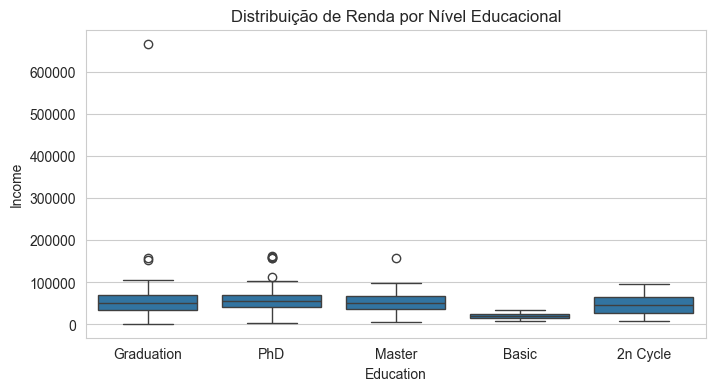

In [30]:
#Distribuição da Renda por Nível Educacional
plt.figure(figsize=(8,4))
sns.boxplot(base, x = 'Education', y='Income')
plt.title('Distribuição de Renda por Nível Educacional')
plt.show()

* <font color='darkblue'>A maior parte dos clientes apresenta renda entre X e Y, com predominância em níveis escolares mais altos, indicando um grupo com maior capacidade de compra. Nota-se que a maioria dos clientes tem renda concentrada em faixas intermediárias, com valores medianos mais altos entre os clientes com um nível de escolaridade mais elevado.</font>

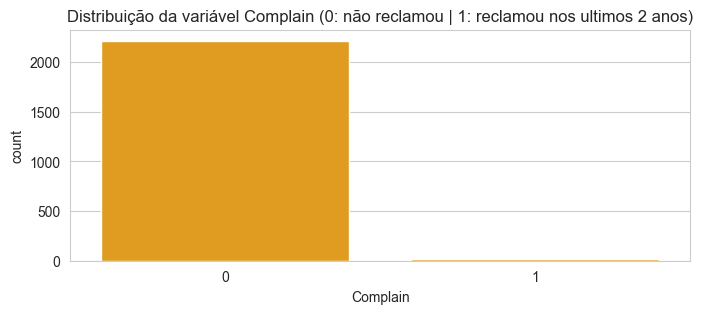

In [31]:
#Comportamento de reclamação dos clientes
contagem = base['Complain'].value_counts()
porcentagem = (contagem / contagem.sum()) * 100

plt.figure(figsize=(8,3))
sns.countplot(data = base, x = 'Complain', color='orange')
plt.title('Distribuição da variável Complain (0: não reclamou | 1: reclamou nos ultimos 2 anos)')
plt.show()

* <font color='darkblue'>A baixa taxa de reclamações indica um alto nível de satisfação geral. A maioria dos clientes está satisfeita com os produtos. Embora seja minoritário, há um grupo de clientes que apresentou reclamações. Essa informação pode ser relevante para modelos preditivos.</font>

In [32]:
#Comportamento dos clientes de acesso e compra no site
cores_personalizadas_1 = [viridis[2], viridis[9]]

base_grouped_1 = base.groupby(['NumStorePurchases', 'WebPurchases']).size().reset_index(name='count')

total_por_NumStorePurchases = base_grouped_1.groupby('NumStorePurchases')['count'].transform('sum')

base_grouped_1['percent'] = (base_grouped_1['count'] / total_por_NumStorePurchases) * 100

# Cria gráfico de barras empilhadas

fig = px.bar(base_grouped_1, x='NumStorePurchases', y='percent', color='WebPurchases', barmode='stack',
             labels={'NumStorePurchases': 'NumStorePurchases', 'percent': 'Porcentagem', 'WebPurchases': 'WebPurchases'},
             color_discrete_sequence=cores_personalizadas_1 )

fig.update_layout(title='Relação entre NumStorePurchases e WebPurchases',
                  yaxis_title='Porcentagem',
                  legend_title='WebPurchases')
fig.show()

* <font color='darkblue'>Nota-se que há muitos acessos ao site regularmente, porém nem sempre as visitas ao site são convertidas em compras. Isso indica que podem ser feitas melhorias na experiência digital, táticas de conversão ou ofertas personalizadas para aumentar o número de acessos que efetuam uma compra.</font>

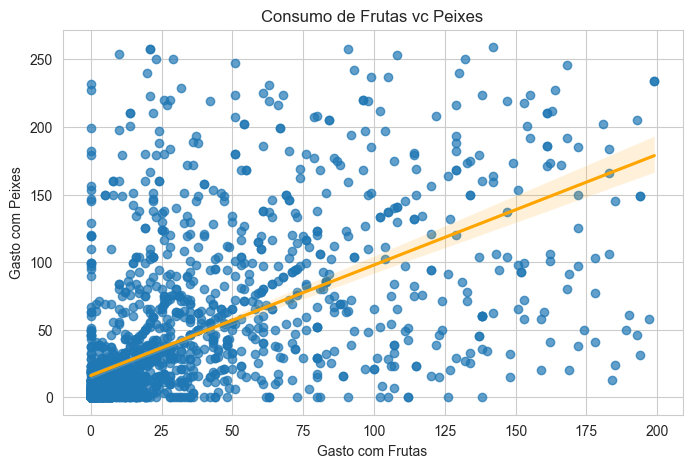

In [33]:
#Comportamento de compras consumo saudavel
plt.figure(figsize=(8,5))
sns.regplot(data = base, x = 'MntFruits', y = 'MntFishProducts', line_kws = {'color': 'orange'}, scatter_kws = {'alpha': 0.7})
plt.title('Consumo de Frutas vc Peixes')
plt.xlabel('Gasto com Frutas')
plt.ylabel('Gasto com Peixes')
plt.show()

* <font color='darkblue'>Podemos observar que clientes que consomem mais frutas tendem também a consumir mais peixe. Esse padrão indica que uma parte dos clientes tem um perfil de consumo mais saudável.</font>

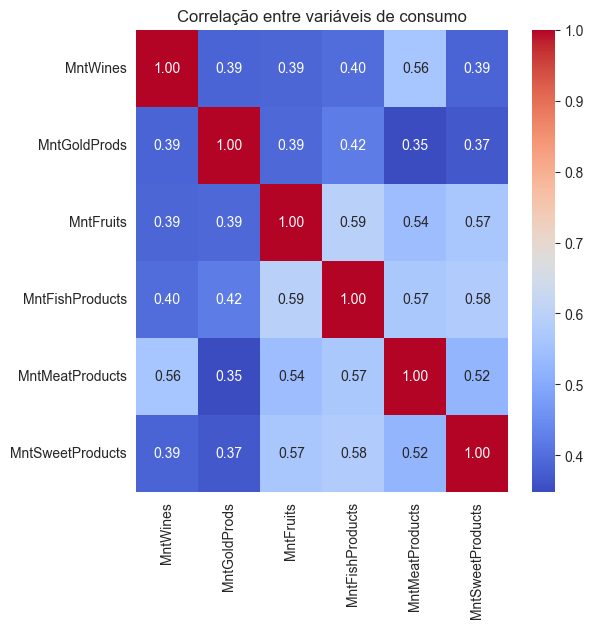

In [34]:
#Comportamento de compras em categorias diferentes

colunas_consumo = ['MntWines', 'MntGoldProds', 'MntFruits', 'MntFishProducts', 'MntMeatProducts', 'MntSweetProducts']
plt.figure(figsize=(6,6))
sns.heatmap(base[colunas_consumo].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlação entre variáveis de consumo')
plt.show()

* <font color='darkblue'>Podemos observar que alguns produtos, como ouro e doces, possuem uma relação mais fraca, enquanto outros, como os vinhos e carnes, têm uma correlação positiva moderada. Isso significa que há comportamentos de consumo distintos entre os clientes.</font>

---------------

# ETAPA 2:
**Pré-processamento**

**Análise Correlação:** Verifique a correlação entre as váriaveis e análise se há espaço para retirar váriaveis que não te parecem importantes.

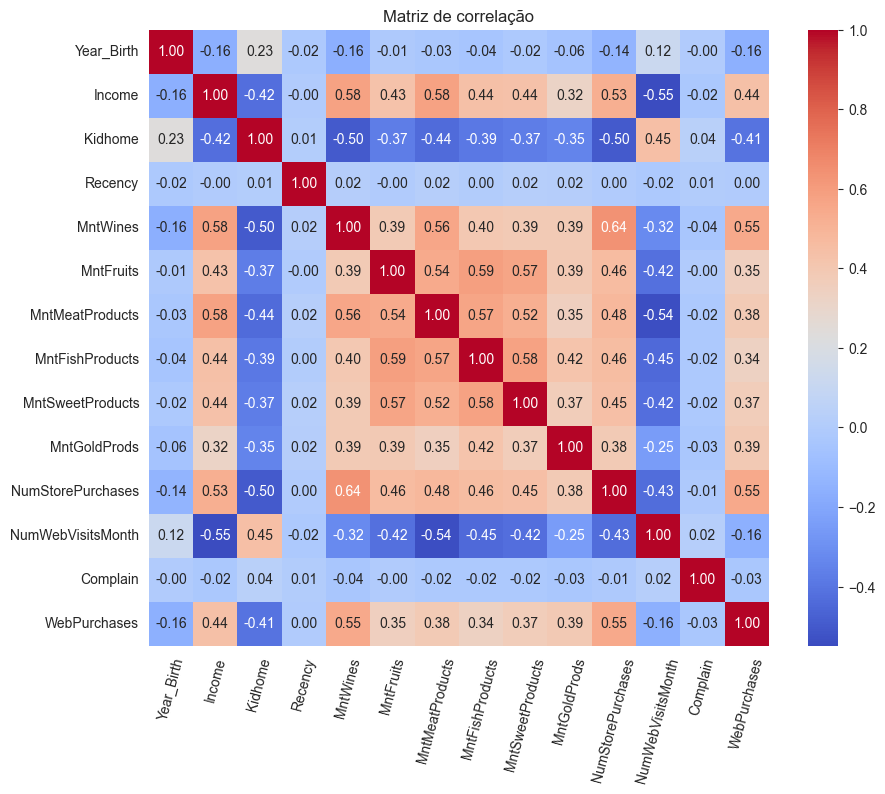

In [35]:
base.select_dtypes(include = ['number']).corr()

correlation_matrix = base.select_dtypes(include = ['number']).corr()
plt.figure(figsize = (10, 8))
sns.heatmap(correlation_matrix, annot = True, cmap = 'coolwarm', fmt = ".2f", annot_kws = {"size": 10})
plt.title('Matriz de correlação')
plt.xticks(rotation=75)
plt.show()

🔹 <font color='darkblue'>Correlação forte: |r|>= 0.59</font>

<font color='darkblue'>➔ Essas variaveis mostram que os clientes com maior poder aquisitivo tendem a consumir mais determinados tipos de produtos,mostrando um padrão de comportamento positivo.</font>
* MntWines e NumStorePurchases 0.64
* MntFruits e MntFishProducts 0.59



🔹 <font color='darkblue'>Correlação moderada: 0.41 <=|r|<= 0.59</font>

<font color='darkblue'>➔ Essas correlações reforçam a relação entre renda, frequencia de compra e comportamento de compra online dos clientes, provando que o poder aquisitivo influencia no volume e diversidade de consumo.</font>
* MntWines e Income 0.58
* Income e MntFishProducts 0.58
* MntFishProducts e MntSweetProducts 0.58
* MntFruits e MntSweetProducts 0.57
* MntMeatProductse e MntFishProducts 0.57
* MntWines e MntMeatProducts 0.56
* MntWines e WebPurchases 0.55
* NumStorePurchase e WebPurchases 0.55
* MntFruits e MntMeatProducts 0.54
* Income e NumStorePurchases 0.53
* MntMeatProducts e MntSweetProducts 0.52
* MntFishProducts e NumStorePurchase 0.46
* MntFruits e NumStorePurchases 0.46
* Kidhome e NumWebVisitsMonth 0.45
* MntSweetProducts e NumStorePurchase 0.45
* Income e MntFishProducts 0.44
* Income e MntSweetProducts 0.44
* Income e WebPurchases 0.44
* Income e MntFruits 0.43
* MntFishProducts e MntGoldProds 0.42



🔹 <font color='darkblue'>Correlação fraca: |r|<= 0.40</font>

<font color='darkblue'>➔ Essa variáveis foram mantidas pois podem contribuir com o treino e teste do machine learning.</font>
* MntWines e MntFishProducts 0.40
* MntWines e MntFruits 0.39
* MntWines e MntGoldProds 0.39
* MntWines e MntSweetProducts 0.39
* MntFruits e MntGoldProds 0.39
* MntGoldProds e WebPurchases 0.39
* MntGoldProds e NumStorePurchase 0.38
* MntMeatProducts e WebPurchases 0.38
* MntSweetProducts e WebPurchases 0.37
* MntSweetProducts e MntGoldProds 0.37
* MntFruits e WebPurchases 0.35
* MntMeatProducts e MntGoldProds 0.35
* MntFishProducts e WebPurchases 0.34

**Codificação de Variáveis Categóricas:** Transformar variáveis categóricas em um formato que os modelos de machine learning possam interpretar.

In [36]:
#Colunas com tratamento one hot: Education, Marital_Status
base = pd.get_dummies(base, columns = ['Education'], prefix = 'Education', drop_first = True)
base = pd.get_dummies(base, columns = ['Marital_Status'], prefix = 'Marital_Status', drop_first = True)

**Separe a base em Y, X e Treino e teste:** Faça a separação da base.

In [37]:
X = base.drop('WebPurchases', axis=1) # X contém todas as colunas exceto 'WebPurchases'
y = base['WebPurchases'] # Y contém apenas a coluna 'WebPurchases'

In [38]:
# Separar em base de treino e teste (usando 70% para treino e 30% para teste)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size= 0.3, random_state= 42, stratify= y)

**Realize a padronização dos dados**: Padronize os dados para garantir eficiência no modelo e eficácia.

* <font color='darkblue'>Embora o pré-processamento inclua a padronização de dados, optei por deixar essa parte para a etapa 3 e utilizar o Pipeline para fazer a padronização. Assim, seria garantido que o StandartScale fosse ajustado apenas nos dados de treino durante a validação cruzada.</font>

------------

# ETAPA 3:

**Modelagem**

Escolha ao menos 2 técnicas de machine learning e rode 2 modelos, afim de identificar qual tem o melhor resultado para essa base. Lembrando que estamos lidando com uma classificação binária.

* <font color='darkblue'>Técnicas de Machine Learning escolhidas: Logistic Regression e Random Forest.</font>

In [39]:
folds = 5

In [40]:
cv = StratifiedKFold(n_splits=folds, shuffle=True, random_state=42)

In [41]:
# Instanciando o modelo de regressão logística
modelo1 = LogisticRegression(max_iter=1000)

In [42]:
# Instanciando o modelo Random Forest
modelo2 = RandomForestClassifier(random_state = 42)

In [43]:
pipeline_modelo1 = ImbPipeline(steps = [('scaler', StandardScaler()), ('smote', SMOTE(random_state=42)), ('model', LogisticRegression(max_iter=1000))])

In [44]:
pipeline_modelo2 = ImbPipeline(steps = [('smote', SMOTE(random_state=42)), ('model', RandomForestClassifier(n_estimators=200, random_state=42))])

In [45]:
#Regressão logística
modelo1 = LogisticRegression(max_iter=1000)
modelo1_final = cross_val_score(pipeline_modelo1, X, y, cv = cv, scoring = 'recall')

C:\Users\marina\anaconda3\envs\jupyter7\lib\site-packages\sklearn\base.py:474: FutureWarning:

`BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.

C:\Users\marina\anaconda3\envs\jupyter7\lib\site-packages\sklearn\base.py:474: FutureWarning:

`BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.

C:\Users\marina\anaconda3\envs\jupyter7\lib\site-packages\sklearn\base.py:474: FutureWarning:

`BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.

C:\Users\marina\anaconda3\envs\jupyter7\lib\site-packages\sklearn\base.py:474: Fut

In [46]:
#Random Forest
modelo2 = RandomForestClassifier(random_state = 42)
modelo2_final = cross_val_score(pipeline_modelo2, X, y, cv = cv, scoring = 'recall')

C:\Users\marina\anaconda3\envs\jupyter7\lib\site-packages\sklearn\base.py:474: FutureWarning:

`BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.

C:\Users\marina\anaconda3\envs\jupyter7\lib\site-packages\sklearn\base.py:474: FutureWarning:

`BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.

C:\Users\marina\anaconda3\envs\jupyter7\lib\site-packages\sklearn\base.py:474: FutureWarning:

`BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.

C:\Users\marina\anaconda3\envs\jupyter7\lib\site-packages\sklearn\base.py:474: Fut

In [47]:
pontuacoes = cross_val_score(pipeline_modelo1, X, y, cv=cv, scoring = 'recall')

print(f"Pontuações por fold Regressão logística: {pontuacoes}")

Pontuações por fold Regressão logística: [0.78318584 0.80088496 0.83555556 0.81333333 0.84888889]


C:\Users\marina\anaconda3\envs\jupyter7\lib\site-packages\sklearn\base.py:474: FutureWarning:

`BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.

C:\Users\marina\anaconda3\envs\jupyter7\lib\site-packages\sklearn\base.py:474: FutureWarning:

`BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.

C:\Users\marina\anaconda3\envs\jupyter7\lib\site-packages\sklearn\base.py:474: FutureWarning:

`BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.

C:\Users\marina\anaconda3\envs\jupyter7\lib\site-packages\sklearn\base.py:474: Fut

In [48]:
pontuacoes = cross_val_score(pipeline_modelo2, X, y, cv=cv, scoring = 'recall')

print(f"Pontuações por fold Random Forest: {pontuacoes}")

C:\Users\marina\anaconda3\envs\jupyter7\lib\site-packages\sklearn\base.py:474: FutureWarning:

`BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.

C:\Users\marina\anaconda3\envs\jupyter7\lib\site-packages\sklearn\base.py:474: FutureWarning:

`BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.

C:\Users\marina\anaconda3\envs\jupyter7\lib\site-packages\sklearn\base.py:474: FutureWarning:

`BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.

C:\Users\marina\anaconda3\envs\jupyter7\lib\site-packages\sklearn\base.py:474: Fut

Pontuações por fold Random Forest: [0.92477876 0.96017699 0.93333333 0.93777778 0.98222222]


In [49]:
print('Regressão logística', modelo1_final.mean())

Regressão logística 0.816369714847591


In [50]:
print('Random Forest:', modelo2_final.mean())

Random Forest: 0.9476578171091445


* <font color='darkblue'>Apesar do modelo de Regressão logística ter aprentado um bom desempenho, com recall de 0.81 o modelo de Random Florest obteve um resultado ainda melhor com o recall de 0.94 sendo assim vamos usar o Random Forest para dar continuidade nas análises.</font>

------------

# ETAPA 4:

**Avaliação**

Avalie os resultados encontrados nos dois modelos e identifique qual te pareceu realizar melhor as previsões.

Utilize além das métricas padrões a matriz de confusão.

In [51]:
#Especificar os hiperparâmetros e seus valores
param_grid = {
    'model__n_estimators': [100, 200, 300],  
    'model__max_depth': [None, 10, 20, 30],  
    'model__min_samples_split': [2, 5, 10],
    'model__min_samples_leaf': [1, 2, 5],
    'model__max_features': ['sqrt', 'log2'],
    'model__class_weight': [None, 'balanced']
}

In [52]:
pipeline_rf = ImbPipeline(steps = [
    ('smote', SMOTE(random_state = 42)),
    ('model', RandomForestClassifier(random_state = 42))
])

In [53]:
# Aplicando o Grid Search
grid_rf = GridSearchCV(estimator=pipeline_rf, param_grid=param_grid, cv=cv, scoring='recall', n_jobs=-1)
grid_rf.fit(X_train, y_train)

C:\Users\marina\anaconda3\envs\jupyter7\lib\site-packages\sklearn\base.py:474: FutureWarning:

`BaseEstimator._validate_data` is deprecated in 1.6 and will be removed in 1.7. Use `sklearn.utils.validation.validate_data` instead. This function becomes public and is part of the scikit-learn developer API.



GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=Pipeline(steps=[('smote', SMOTE(random_state=42)),
                                       ('model',
                                        RandomForestClassifier(random_state=42))]),
             n_jobs=-1,
             param_grid={'model__class_weight': [None, 'balanced'],
                         'model__max_depth': [None, 10, 20, 30],
                         'model__max_features': ['sqrt', 'log2'],
                         'model__min_samples_leaf': [1, 2, 5],
                         'model__min_samples_split': [2, 5, 10],
                         'model__n_estimators': [100, 200, 300]},
             scoring='recall')

In [54]:
# Melhores parâmetros encontrados
best_estimator = grid_rf.best_estimator_
print(f"Melhores parâmetros: {best_estimator}")

Melhores parâmetros: Pipeline(steps=[('smote', SMOTE(random_state=42)),
                ('model',
                 RandomForestClassifier(max_depth=10, min_samples_split=5,
                                        n_estimators=200, random_state=42))])


In [55]:
y_pred = best_estimator.predict(X_test)

relatorio = classification_report(y_test, y_pred)

print("Acurácia:", accuracy_score(y_test, y_pred))
print("\n Matriz de confusão:\n", confusion_matrix(y_test, y_pred))
print("\n Relatório de Classificação:\n", relatorio)

Acurácia: 0.9032738095238095

 Matriz de confusão:
 [[286  47]
 [ 18 321]]

 Relatório de Classificação:
               precision    recall  f1-score   support

           0       0.94      0.86      0.90       333
           1       0.87      0.95      0.91       339

    accuracy                           0.90       672
   macro avg       0.91      0.90      0.90       672
weighted avg       0.91      0.90      0.90       672



➔ <font color='darkblue'>Matriz de confusão:
* verdedeiro positivo = 321
* falso negativo = 18
* falso positivo = 47</font>

➔ <font color='darkblue'>Acurácia = 0.90</font>

➔ <font color='darkblue'>recall = 0.95</font>

➔ <font color='darkblue'>f1-score = 0.91</font>


* <font color='darkblue'>Os modelos de Regressão Logística e Random Florest foram analisados utilizando métricas de classificação, sendo o recall a principal delas, pois o objetivo é identificar com precisão os clientes que possuem intenção de comprar.</font>

* <font color='darkblue'>A Regressão Logística exibiu um desempenho positivo, tendo um recall de 0.81, o que indica uma boa capacidade preditiva. Contudo, o modelo Random Florest apresentou um desempenho melhor com um recall de 0.94 após a otimização dos hiperparâmetros. Ao analisarmos a matriz de confusão do Random Florest vemos um grande número de verdadeiros positivos e um pequeno de falsos negativos, o que sugere que o modelo é capaz de identificar os clientes corretamente. A precisão geral do modelo foi 90%, o que reforça a consistência dos resultados.</font>

* <font color='darkblue'>Assim, o modelo Random Florest foi escolhido como modelo final do projeto, pois demonstrou maior desempenho na identificação de clientes mais propensos a realizar compras online.</font>

---------------